In [1]:

from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import DecisionBoundaryDisplay, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, mean_absolute_error, mean_squared_error, roc_auc_score
from sklearn.model_selection import (
    GridSearchCV, KFold, StratifiedKFold, cross_val_score, train_test_split,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

PROJECT_ROOT = Path.cwd().parent
DATA = PROJECT_ROOT / "all_datasets"
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)


In [2]:

print("Project root:", PROJECT_ROOT)
print("Dataset folder exists:", DATA.exists())
print("Models folder exists:", MODELS.exists())

required_files = [
    "breast_cancer_dataset.csv",
    "titanic_dataset.csv",
    "ames_housing_dataset.csv",
    "red_wine_quality_dataset.csv",
]

for filename in required_files:
    print(filename, ":", (DATA / filename).exists())


Project root: C:\Users\User HP\Desktop\ML_Course
Dataset folder exists: True
Models folder exists: True
breast_cancer_dataset.csv : True
titanic_dataset.csv : True
ames_housing_dataset.csv : True
red_wine_quality_dataset.csv : True


In [3]:

cancer = pd.read_csv(DATA / "breast_cancer_dataset.csv")

X_c = cancer.drop(
    columns=["id", "diagnosis", "Unnamed: 32"],
    errors="ignore"
)
y_c = (cancer["diagnosis"] == "M").astype(int)

Xc_train, Xc_valid, yc_train, yc_valid = train_test_split(
    X_c, y_c, test_size=0.25, random_state=42, stratify=y_c
)


k= 1 cross-validated ROC AUC = 0.946
k= 3 cross-validated ROC AUC = 0.984
k= 5 cross-validated ROC AUC = 0.985
k= 7 cross-validated ROC AUC = 0.987
k=11 cross-validated ROC AUC = 0.988
k=21 cross-validated ROC AUC = 0.988
selected k: 11


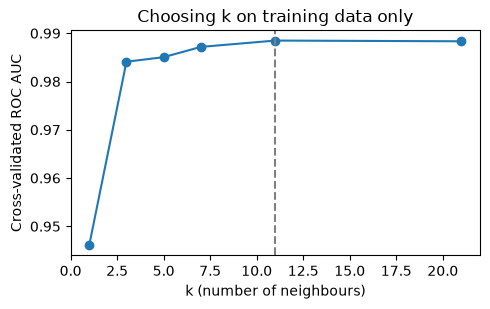

In [4]:

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
k_values = [1, 3, 5, 7, 11, 21]
cv_scores = {}

for k in k_values:
    candidate = Pipeline([
        ("scale", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=k, weights="distance")),
    ])
    scores = cross_val_score(
        candidate, Xc_train, yc_train, cv=cv, scoring="roc_auc"
    )
    cv_scores[k] = scores.mean()
    print(f"k={k:2d} cross-validated ROC AUC = {scores.mean():.3f}")

best_k = max(cv_scores, key=cv_scores.get)
print("selected k:", best_k)

plt.figure(figsize=(5, 3.2))
plt.plot(k_values, [cv_scores[k] for k in k_values], marker="o")
plt.axvline(best_k, linestyle="--", color="grey")
plt.xlabel("k (number of neighbours)")
plt.ylabel("Cross-validated ROC AUC")
plt.title("Choosing k on training data only")
plt.tight_layout()
plt.show()


In [5]:

knn = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsClassifier(
        n_neighbors=best_k, weights="distance"
    )),
])

gnb = Pipeline([
    ("scale", StandardScaler()),
    ("model", GaussianNB()),
])

models_a = {
    "KNN": knn,
    "Gaussian Naive Bayes": gnb,
}

for name, model in models_a.items():
    model.fit(Xc_train, yc_train)
    probabilities = model.predict_proba(Xc_valid)[:, 1]
    predictions = model.predict(Xc_valid)

    print(
        f"{name:22s} "
        f"Accuracy = {accuracy_score(yc_valid, predictions):.3f} | "
        f"ROC AUC = {roc_auc_score(yc_valid, probabilities):.3f}"
    )


KNN                    Accuracy = 0.958 | ROC AUC = 0.986
Gaussian Naive Bayes   Accuracy = 0.944 | ROC AUC = 0.992


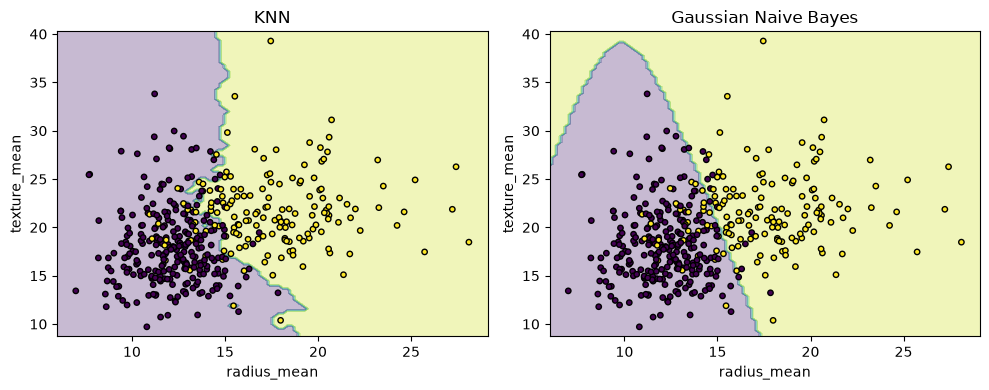

In [8]:

features_2d = ["radius_mean", "texture_mean"]

X2 = cancer[features_2d]
X2_train, X2_valid, y2_train, y2_valid = train_test_split(
    X2, y_c, test_size=0.25, random_state=42, stratify=y_c
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (name, classifier) in zip(
    axes,
    [
        ("KNN", KNeighborsClassifier(n_neighbors=best_k, weights="distance")),
        ("Gaussian Naive Bayes", GaussianNB()),
    ],
):
    pipeline = Pipeline([
        ("scale", StandardScaler()),
        ("model", classifier),
    ])
    pipeline.fit(X2_train, y2_train)

    DecisionBoundaryDisplay.from_estimator(
        pipeline,
        X2_train,
        response_method="predict",
        plot_method="contourf",
        alpha=0.3,
        ax=ax,
    )

    ax.scatter(
        X2_train[features_2d[0]],
        X2_train[features_2d[1]],
        c=y2_train,
        edgecolor="k",
        s=15,
    )
    ax.set_title(name)
    ax.set_xlabel(features_2d[0])
    ax.set_ylabel(features_2d[1])

plt.tight_layout()
plt.show()


In [9]:

titanic = pd.read_csv(DATA / "titanic_dataset.csv")

print("Shape:", titanic.shape)
print("Columns:", titanic.columns.tolist())
print(titanic.head())


Shape: (891, 12)
Columns: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2.

In [10]:

print(titanic.dtypes)
print(titanic["Survived"].value_counts(dropna=False))


PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object
Survived
0    549
1    342
Name: count, dtype: int64


In [11]:

target = "Survived"

feature_cols = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
X_t = titanic[feature_cols]
y_t = titanic[target]

num_cols = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
cat_cols = ["Sex", "Embarked"]

Xt_train, Xt_valid, yt_train, yt_valid = train_test_split(
    X_t, y_t, test_size=0.25, random_state=42, stratify=y_t
)

print("Training shape:", Xt_train.shape)
print("Validation shape:", Xt_valid.shape)
print("Missing values in training:")
print(Xt_train.isna().sum())


Training shape: (668, 7)
Validation shape: (223, 7)
Missing values in training:
Pclass        0
Sex           0
Age         131
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64


In [12]:

preprocess_t = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), cat_cols),
])

tree_model = Pipeline([
    ("preprocess", preprocess_t),
    ("model", DecisionTreeClassifier(max_depth=3, random_state=42)),
])

tree_model.fit(Xt_train, yt_train)
tree_pred = tree_model.predict(Xt_valid)

print("Validation accuracy:", round(accuracy_score(yt_valid, tree_pred), 3))
print("Tree depth:", tree_model.named_steps["model"].get_depth())
print("Number of leaves:", tree_model.named_steps["model"].get_n_leaves())


Validation accuracy: 0.785
Tree depth: 3
Number of leaves: 8


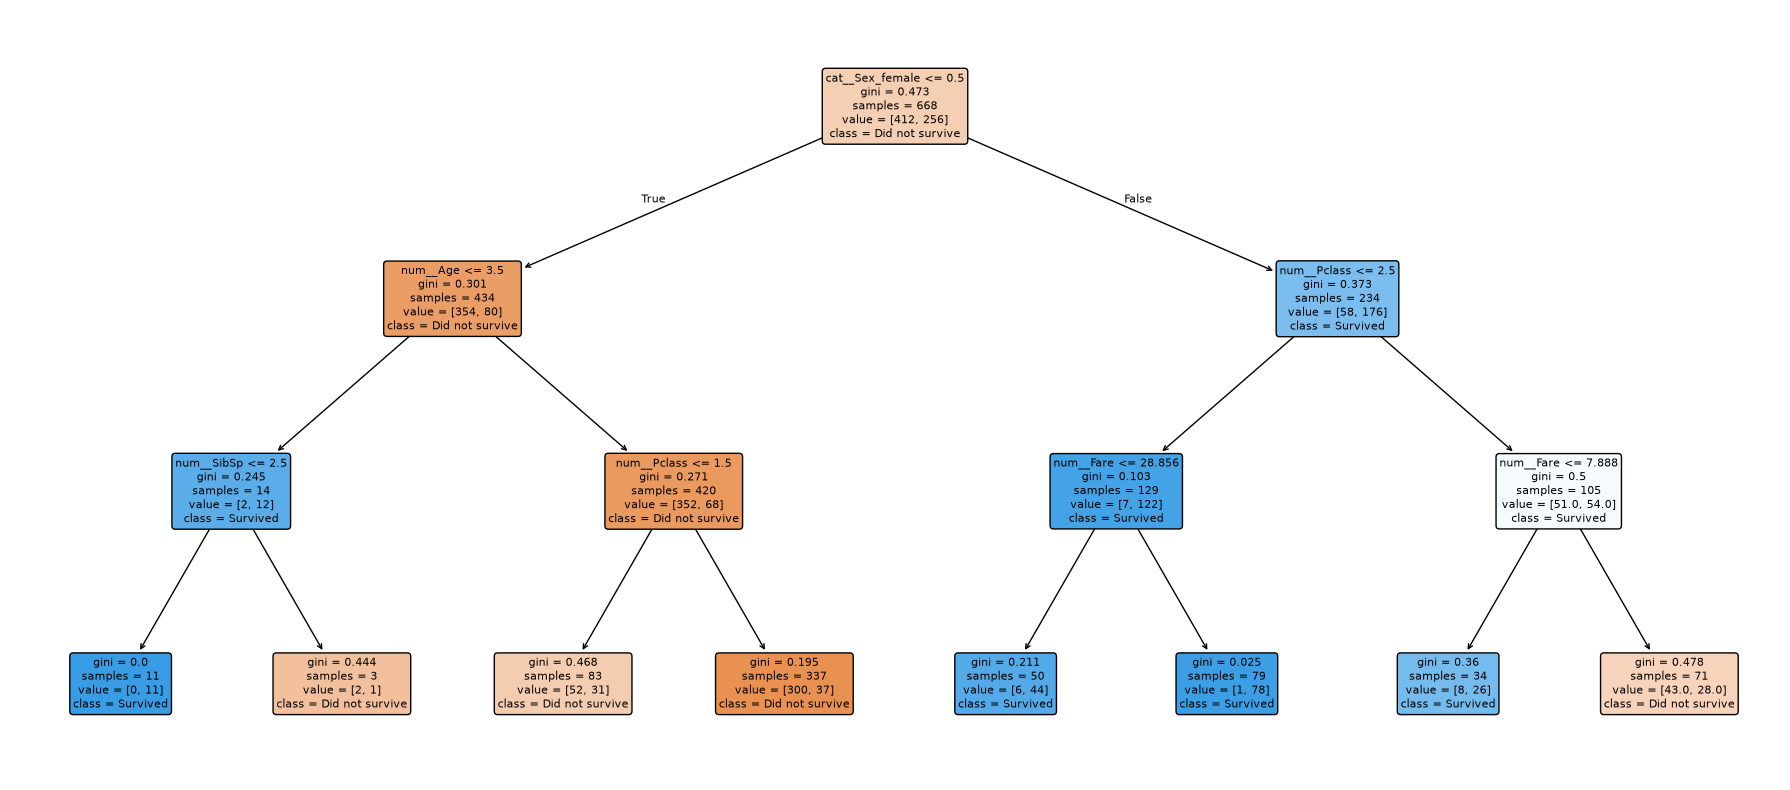

In [13]:

feature_names = tree_model.named_steps["preprocess"].get_feature_names_out()

plt.figure(figsize=(18, 8))
plot_tree(
    tree_model.named_steps["model"],
    feature_names=feature_names,
    class_names=["Did not survive", "Survived"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8,
)
plt.tight_layout()
plt.show()


In [14]:

depths = [1, 2, 3, 4, 5, 7, 10, None]
depth_results = []

for depth in depths:
    model = Pipeline([
        ("preprocess", preprocess_t),
        ("model", DecisionTreeClassifier(
            max_depth=depth, random_state=42
        )),
    ])

    model.fit(Xt_train, yt_train)

    train_accuracy = accuracy_score(
        yt_train, model.predict(Xt_train)
    )
    valid_accuracy = accuracy_score(
        yt_valid, model.predict(Xt_valid)
    )

    depth_results.append({
        "max_depth": str(depth),
        "training_accuracy": train_accuracy,
        "validation_accuracy": valid_accuracy,
    })

depth_df = pd.DataFrame(depth_results)
print(depth_df.round(3).to_string(index=False))


max_depth  training_accuracy  validation_accuracy
        1              0.793                0.767
        2              0.808                0.758
        3              0.832                0.785
        4              0.852                0.780
        5              0.868                0.771
        7              0.892                0.771
       10              0.939                0.740
     None              0.978                0.731


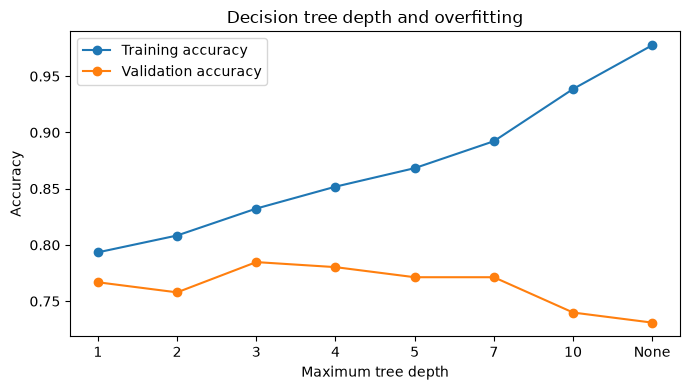

In [15]:

plt.figure(figsize=(7, 4))

plt.plot(
    depth_df["max_depth"],
    depth_df["training_accuracy"],
    marker="o",
    label="Training accuracy",
)
plt.plot(
    depth_df["max_depth"],
    depth_df["validation_accuracy"],
    marker="o",
    label="Validation accuracy",
)

plt.xlabel("Maximum tree depth")
plt.ylabel("Accuracy")
plt.title("Decision tree depth and overfitting")
plt.legend()
plt.tight_layout()
plt.show()


In [16]:

ames = pd.read_csv(DATA / "ames_housing_dataset.csv")

X_a = ames.drop(columns=["SalePrice", "Order", "PID"], errors="ignore")
y_a = np.log1p(ames["SalePrice"])

ames_preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"),
     X_a.select_dtypes(include="number").columns),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore", sparse_output=False
        )),
    ]), X_a.select_dtypes(exclude="number").columns),
])

print("Dataset shape:", ames.shape)
print("Features:", X_a.shape[1])
print("Target: log(1 + SalePrice)")
print("Missing values in target:", y_a.isna().sum())


Dataset shape: (2930, 82)
Features: 79
Target: log(1 + SalePrice)
Missing values in target: 0


In [17]:

ensembles = {
    "random_forest": RandomForestRegressor(
        n_estimators=150,
        max_features=0.8,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1,
    ),
    "gradient_boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        loss="huber",
        random_state=42,
    ),
}

cv3 = KFold(n_splits=3, shuffle=True, random_state=42)
cv_rmse = {}

for name, estimator in ensembles.items():
    pipe = Pipeline([
        ("preprocess", ames_preprocess),
        ("model", estimator),
    ])

    neg_mse = cross_val_score(
        pipe, X_a, y_a, cv=cv3,
        scoring="neg_mean_squared_error",
    )

    cv_rmse[name] = np.sqrt(-neg_mse)

    print(
        f"{name:18s} CV log-RMSE = "
        f"{cv_rmse[name].mean():.4f} +/- "
        f"{cv_rmse[name].std():.4f}"
    )


random_forest      CV log-RMSE = 0.1382 +/- 0.0118
gradient_boosting  CV log-RMSE = 0.1273 +/- 0.0141


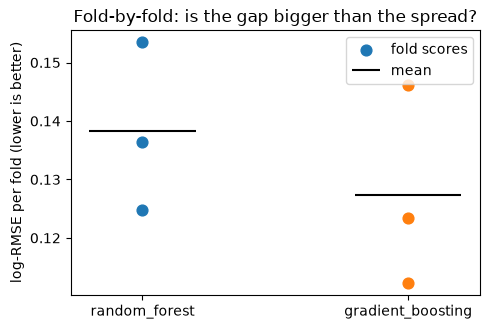

In [18]:

plt.figure(figsize=(5, 3.4))

for i, (name, values) in enumerate(cv_rmse.items()):
    plt.scatter(
        [i] * len(values), values, s=60,
        label="fold scores" if i == 0 else None,
    )
    plt.hlines(
        values.mean(), i - 0.2, i + 0.2,
        color="black", label="mean" if i == 0 else None,
    )

plt.xticks(range(len(cv_rmse)), list(cv_rmse))
plt.ylabel("log-RMSE per fold (lower is better)")
plt.title("Fold-by-fold: is the gap bigger than the spread?")
plt.legend()
plt.tight_layout()
plt.show()


In [19]:

wine = pd.read_csv(DATA / "red_wine_quality_dataset.csv")

X_w = wine.drop(columns="quality")
y_w = wine["quality"]

Xw_train, Xw_valid, yw_train, yw_valid = train_test_split(
    X_w, y_w, test_size=0.25, random_state=42
)

wine_models = {
    "random_forest": RandomForestRegressor(
        n_estimators=400,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1,
    ),
    "gradient_boosting": GradientBoostingRegressor(
        random_state=42
    ),
}

wine_pred = {}

for name, model in wine_models.items():
    model.fit(Xw_train, yw_train)
    wine_pred[name] = model.predict(Xw_valid)

    print(
        f"{name:18s} "
        f"MAE = {mean_absolute_error(yw_valid, wine_pred[name]):.3f}   "
        f"RMSE = {np.sqrt(mean_squared_error(yw_valid, wine_pred[name])):.3f}"
    )


random_forest      MAE = 0.432   RMSE = 0.565
gradient_boosting  MAE = 0.476   RMSE = 0.597


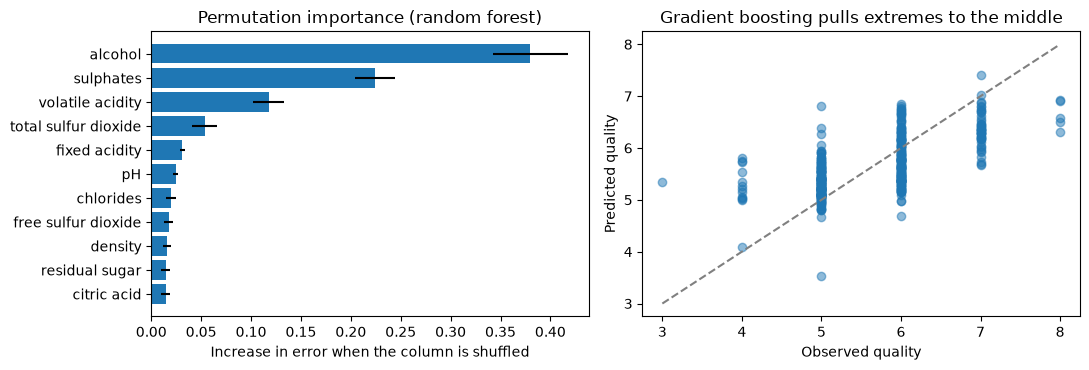

In [20]:

importance = permutation_importance(
    wine_models["random_forest"],
    Xw_valid,
    yw_valid,
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
)

ranked = pd.Series(
    importance.importances_mean,
    index=X_w.columns
).sort_values()

spread = importance.importances_std[
    np.argsort(importance.importances_mean)
]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].barh(ranked.index, ranked.values, xerr=spread)
axes[0].set_xlabel("Increase in error when the column is shuffled")
axes[0].set_title("Permutation importance (random forest)")

axes[1].scatter(
    yw_valid, wine_pred["gradient_boosting"], alpha=0.5
)
axes[1].plot(
    [3, 8], [3, 8], linestyle="--", color="grey"
)
axes[1].set_xlabel("Observed quality")
axes[1].set_ylabel("Predicted quality")
axes[1].set_title("Gradient boosting pulls extremes to the middle")

plt.tight_layout()
plt.show()


In [21]:

X_train, X_test, y_train, y_test = train_test_split(
    X_c, y_c, test_size=0.25,
    random_state=42, stratify=y_c
)

svm_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC()),
])

search = GridSearchCV(
    svm_pipe,
    param_grid={
        "model__kernel": ["linear", "rbf"],
        "model__C": [0.1, 1, 10, 100],
        "model__gamma": ["scale", 0.01, 0.1],
    },
    cv=StratifiedKFold(
        5, shuffle=True, random_state=42
    ),
    scoring="roc_auc",
    n_jobs=-1,
)

search.fit(X_train, y_train)

score = search.decision_function(X_test)
pred = search.predict(X_test)

print("best parameters:", search.best_params_)
print("cross-validated ROC AUC:", round(search.best_score_, 3))
print("test accuracy:", round(accuracy_score(y_test, pred), 3))
print("test ROC AUC:", round(roc_auc_score(y_test, score), 3))


best parameters: {'model__C': 10, 'model__gamma': 0.01, 'model__kernel': 'rbf'}
cross-validated ROC AUC: 0.995
test accuracy: 0.979
test ROC AUC: 0.997


In [24]:

two = ["radius_mean", "texture_mean"]


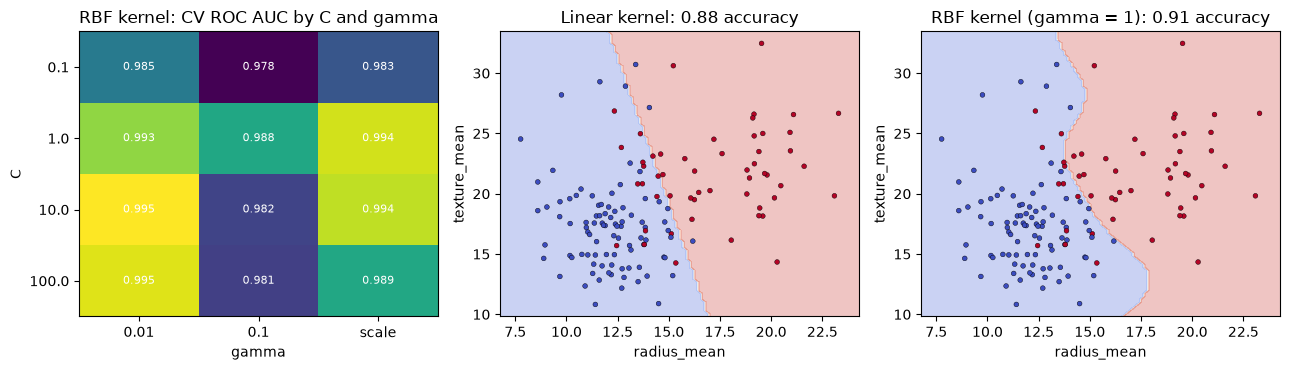

In [25]:

results = pd.DataFrame(search.cv_results_)

rbf = results[
    results["param_model__kernel"] == "rbf"
].copy()

rbf["gamma"] = rbf["param_model__gamma"].astype(str)

grid = rbf.pivot(
    index="param_model__C",
    columns="gamma",
    values="mean_test_score",
)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

im = axes[0].imshow(
    grid.values, cmap="viridis", aspect="auto"
)
axes[0].set_xticks(range(len(grid.columns)), grid.columns)
axes[0].set_yticks(range(len(grid.index)), grid.index)
axes[0].set_xlabel("gamma")
axes[0].set_ylabel("C")

for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        axes[0].text(
            j, i, f"{grid.values[i, j]:.3f}",
            ha="center", va="center",
            color="white", fontsize=8,
        )

axes[0].set_title("RBF kernel: CV ROC AUC by C and gamma")

for ax, (title, estimator) in zip(axes[1:], [
    ("Linear kernel", SVC(kernel="linear", C=1)),
    ("RBF kernel (gamma = 1)", SVC(kernel="rbf", C=1, gamma=1.0)),
]):
    small = Pipeline([
        ("scale", StandardScaler()),
        ("model", estimator),
    ]).fit(X_train[two], y_train)

    DecisionBoundaryDisplay.from_estimator(
        small, X_test[two], ax=ax,
        alpha=0.3, response_method="predict",
        cmap="coolwarm",
    )

    ax.scatter(
        X_test[two[0]], X_test[two[1]],
        c=y_test, cmap="coolwarm",
        s=12, edgecolor="k", linewidth=0.3,
    )

    ax.set_title(
        f"{title}: {accuracy_score(y_test, small.predict(X_test[two])):.2f} accuracy"
    )
    ax.set_xlabel("radius_mean")
    ax.set_ylabel("texture_mean")

plt.tight_layout()
plt.show()


In [26]:

model_path = MODELS / "breast_cancer_svm.joblib"

joblib.dump(search.best_estimator_, model_path)
loaded = joblib.load(model_path)

same = np.array_equal(loaded.predict(X_test), pred)

print("Model saved:", model_path.exists())
print("Model reload predictions match:", same)


Model saved: True
Model reload predictions match: True
